# DDPG Agent Testing Guide on Pendulum-v1

- Deep Deterministic Policy Gradient (DDPG) is an actor-critic, off-policy algorithm designed for continuous action spaces.
- Unlike policy gradient algorithms with stochastic policies (like REINFORCE or PPO), DDPG learns a deterministic target policy $\mu(s)$ and uses an off-policy replay buffer along with slowly updating target networks (soft update $\tau$) to stabilize training.

This notebook provides a minimal workflow for testing a Deep Deterministic Policy Gradient (DDPG) agent on `Pendulum-v1`. It configures the experiment, trains the agent, evaluates the deterministic policy, and prints the metrics returned by `learn()`. The cells are intended to be edited and rerun while experimenting with the agent and its hyperparameters.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import gymnasium as gym
import numpy as np
import deep_rl

DEEP_RL_DIR = Path(deep_rl.__file__).resolve().parent
POLICY_GRADIENT_DIR = DEEP_RL_DIR / 'policy_gradient'  # runs/ output lives here

from deep_rl.continuous_control.ddpg import DDPG


## 1. Configure the Experiment

Adjust these values before running the training cell. Start with a small `MAX_STEPS` while debugging, then increase it for longer experiments.

In [3]:
ENV_ID = 'Pendulum-v1'
SEED = 2026
MAX_STEPS = 20_000
START_STEPS = 1_000
BUFFER_SIZE = 100_000
BATCH_SIZE = 64
ACTOR_HIDDEN_DIMS = (256, 256)
CRITIC_HIDDEN_DIMS = (256, 256)
ACTOR_LR = 1e-4
CRITIC_LR = 1e-3
GAMMA = 0.99
TAU = 0.005
EXPLORATION_NOISE = 0.1

print(f'Environment: {ENV_ID}')
print(f'Seed: {SEED}')
print(f'Total steps: {MAX_STEPS}')
print(f'Warmup (start) steps: {START_STEPS}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Soft update tau: {TAU}')


Environment: Pendulum-v1
Seed: 2026
Total steps: 20000
Warmup (start) steps: 1000
Batch size: 64
Soft update tau: 0.005


## 2. Create the Environment and Train DDPG

DDPG adds exploration noise to its deterministic policy during training and evaluates without noise.

In [4]:
env = gym.make(ENV_ID)
env.reset(seed=SEED)
env.action_space.seed(SEED)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
max_action = float(env.action_space.high[0])

agent = DDPG(
    state_dim=state_dim,
    action_dim=action_dim,
    max_action=max_action,
    actor_hidden_dims=ACTOR_HIDDEN_DIMS,
    critic_hidden_dims=CRITIC_HIDDEN_DIMS,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    gamma=GAMMA,
    tau=TAU,
    buffer_size=BUFFER_SIZE,
    batch_size=BATCH_SIZE,
    start_steps=START_STEPS,
    exploration_noise=EXPLORATION_NOISE,
    seed=SEED,
)

print(f'State dim: {state_dim}, Action dim: {action_dim}, Max action: {max_action}')
metrics = agent.learn(env, max_steps=MAX_STEPS)

print('Training metrics:')
for name, value in metrics.items():
    print(f'  {name}: {value}')


State dim: 3, Action dim: 1, Max action: 2.0
Training metrics:
  actor_loss: 37.639186754586675
  critic_loss: 2.527510107976163
  q_value: -39.36533605064582
  episode_return: -360.16025091109304
  episode_length: 200.0
  total_steps: 20000


## 3. Inspect the Training Metrics

`DDPG.learn()` returns aggregate information from network updates and completed training episodes. The next cell prints a short explanation for each metric.

In [5]:
metric_descriptions = {
    'actor_loss': 'Mean negative Q-value objective (-Q(s, mu(s))). As policy improves, this tends to decrease.',
    'critic_loss': 'Value-function prediction error (Bellman mean squared error).',
    'q_value': 'Average estimated Q-value over the sampled training mini-batches.',
    'episode_return': 'Average episode return during training with exploration noise.',
    'episode_length': 'Average episode duration in steps.',
    'total_steps': 'Total environment interaction steps taken.',
}

for name, description in metric_descriptions.items():
    print(f'{name}: {metrics.get(name, 0.0)}')
    print(f'  {description}')


actor_loss: 37.639186754586675
  Mean negative Q-value objective (-Q(s, mu(s))). As policy improves, this tends to decrease.
critic_loss: 2.527510107976163
  Value-function prediction error (Bellman mean squared error).
q_value: -39.36533605064582
  Average estimated Q-value over the sampled training mini-batches.
episode_return: -360.16025091109304
  Average episode return during training with exploration noise.
episode_length: 200.0
  Average episode duration in steps.
total_steps: 20000
  Total environment interaction steps taken.


## 4. Evaluate the Deterministic Policy

Evaluation tests the learned deterministic policy without adding exploration noise.

In [6]:
evaluation_env = gym.make(ENV_ID)
evaluation_env.reset(seed=SEED + 1)
evaluation_env.action_space.seed(SEED + 1)
evaluation_return = agent.evaluate(evaluation_env, num_episodes=2)
evaluation_env.close()
env.close()

print(f'Mean evaluation return over 2 episodes: {evaluation_return:.3f}')
assert isinstance(evaluation_return, float)

Mean evaluation return over 2 episodes: -117.761


## 5. Hyperparameter Tuning

DDPG extends Deep Q-Networks (DQN) to continuous action spaces using an Actor-Critic architecture. The techniques used to keep policy and value updates stable include:
- Using a deterministic actor $\mu(s)$ bounded by the environment\'s action limits (`max_action * Tanh(x)`)
- Off-policy replay buffer to break correlation between consecutive transitions
- Target networks with soft update for both Actor and Critic
- Adding exploratory noise (Gaussian is commonly used) during interaction

So the hyperparameters we need to choose carefully for this agent include:
- **The learning rate for actor and critic**: `critic_lr` is usually larger than `actor_lr` (e.g. `1e-3` vs `1e-4`) to ensure the Q-function converges quickly and guides policy gradient updates accurately.
- **Actor and Critic network architecture**: Typically a 2-layer MLP like `(256, 256)` is a good starting point for control tasks like Pendulum.
- **Soft update coefficient (`tau`)**: Controls how slowly target networks follow the active networks (typically `0.001` - `0.005`). A small value prevents divergence.
- **Discount factor (`gamma`)**: Controls the agent\'s planning horizon (e.g. `0.99`).
- **Warmup (`start_steps`)**: Number of initial steps taking uniform random actions to populate the replay buffer before performing gradient updates.
- **Exploration noise**: Controls the exploration level. Too large and actions remain erratic; too small and the agent may get trapped in local optima.

## 6. Visualize Trained Agent Performance

Run the trained policy on a newly seeded `Pendulum-v1` instance, record RGB frames, and render the resulting episode as an animated GIF.

Visual evaluation episode completed with total return: -117.21


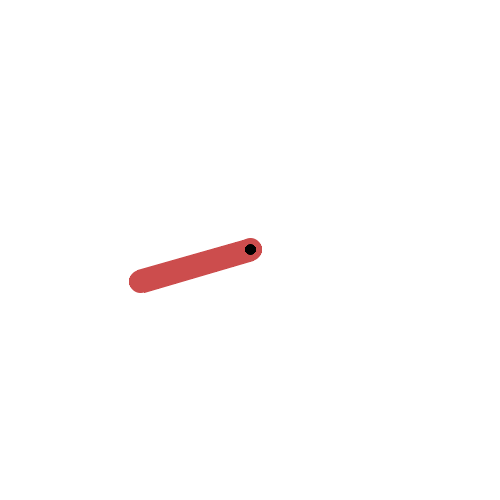

In [ ]:
import imageio
from IPython.display import Image, display

def visualize_agent(agent, env_id=ENV_ID, seed=SEED + 42, gif_path='assets/pendulum_ddpg.gif', fps=30):
    vis_env = gym.make(env_id, render_mode="rgb_array")
    state, _ = vis_env.reset(seed=seed)
    vis_env.action_space.seed(seed)

    frames = [vis_env.render()]
    episode_reward = 0.0
    done = False

    while not done:
        action = agent.select_action(state, add_noise=False)
        state, reward, terminated, truncated, _ = vis_env.step(action)
        episode_reward += reward
        frames.append(vis_env.render())
        done = terminated or truncated

    vis_env.close()
    imageio.mimsave(gif_path, frames, fps=fps, loop=0)
    print(f"Visual evaluation episode completed with total return: {episode_reward:.2f}")
    return Image(filename=gif_path)

display(visualize_agent(agent))
